<a href="https://colab.research.google.com/github/PoletteRamirez/data-science-portfolio/blob/main/Retail_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Project_1_Retail_Sales_Dataset.csv")

df.head()

,order_id,order_date,product,category,quantity,unit_price_usd,discount_pct,city,payment_method,sales_usd
0,ORD-0001,2026-05-21,Mechanical Keyboard,Accessories,1,59.9,0.00,Chihuahua,Debit Card,59.90
1,ORD-0002,2026-02-14,Mechanical Keyboard,Accessories,5,59.9,0.15,Guadalajara,Credit Card,254.57
2,ORD-0003,2026-04-22,Wireless Mouse,Accessories,1,18.5,0.00,Mexico City,Credit Card,18.50
3,ORD-0004,2026-10-07,Monitor 24in,Electronics,2,145.0,0.10,Chihuahua,PayPal,261.00
4,ORD-0005,2026-01-04,Webcam,Electronics,3,48.0,0.00,Tijuana,PayPal,144.00


In [3]:
from google.colab import files
uploaded = files.upload()

Saving Project_1_Retail_Sales_Dataset.csv to Project_1_Retail_Sales_Dataset.csv


In [5]:

df.head()

,order_id,order_date,product,category,quantity,unit_price_usd,discount_pct,city,payment_method,sales_usd
0,ORD-0001,2026-05-21,Mechanical Keyboard,Accessories,1,59.9,0.00,Chihuahua,Debit Card,59.90
1,ORD-0002,2026-02-14,Mechanical Keyboard,Accessories,5,59.9,0.15,Guadalajara,Credit Card,254.57
2,ORD-0003,2026-04-22,Wireless Mouse,Accessories,1,18.5,0.00,Mexico City,Credit Card,18.50
3,ORD-0004,2026-10-07,Monitor 24in,Electronics,2,145.0,0.10,Chihuahua,PayPal,261.00
4,ORD-0005,2026-01-04,Webcam,Electronics,3,48.0,0.00,Tijuana,PayPal,144.00


In [6]:

print("Filas y columnas:", df.shape)

print(df.columns)

df.info()

Filas y columnas: (80, 10)
Index(['order_id', 'order_date', 'product', 'category', 'quantity',
       'unit_price_usd', 'discount_pct', 'city', 'payment_method',
       'sales_usd'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        80 non-null     object 
 1   order_date      80 non-null     object 
 2   product         80 non-null     object 
 3   category        80 non-null     object 
 4   quantity        80 non-null     int64  
 5   unit_price_usd  80 non-null     float64
 6   discount_pct    80 non-null     float64
 7   city            80 non-null     object 
 8   payment_method  80 non-null     object 
 9   sales_usd       80 non-null     float64
dtypes: float64(3), int64(1), object(6)
memory usage: 6.4+ KB


In [7]:
print("Valores vacíos:")
print(df.isnull().sum())
print("Registros duplicados:", df.duplicated().sum())

Valores vacíos:
order_id          0
order_date        0
product           0
category          0
quantity          0
unit_price_usd    0
discount_pct      0
city              0
payment_method    0
sales_usd         0
dtype: int64
Registros duplicados: 0


In [8]:
total_ventas = df["sales_usd"].sum()

print("Ventas totales: $", round(total_ventas, 2))

Ventas totales: $ 10421.15


In [9]:
ventas_producto = df.groupby("product")["sales_usd"].sum()

ventas_producto = ventas_producto.sort_values(ascending=False)

print(ventas_producto)

product
Monitor 24in           4516.75
Mechanical Keyboard    1407.63
Webcam                 1219.20
USB-C Hub               872.00
Backpack                731.25
Laptop Stand            607.74
Desk Lamp               406.35
Wireless Mouse          314.50
Water Bottle            251.18
Notebook                 94.55
Name: sales_usd, dtype: float64


In [10]:
ventas_ciudad = df.groupby("city")["sales_usd"].sum()

print(ventas_ciudad.sort_values(ascending=False))

city
Ciudad Juárez    2786.73
Chihuahua        2321.91
Guadalajara      1627.00
Tijuana          1286.90
Mexico City      1275.34
Monterrey        1123.27
Name: sales_usd, dtype: float64


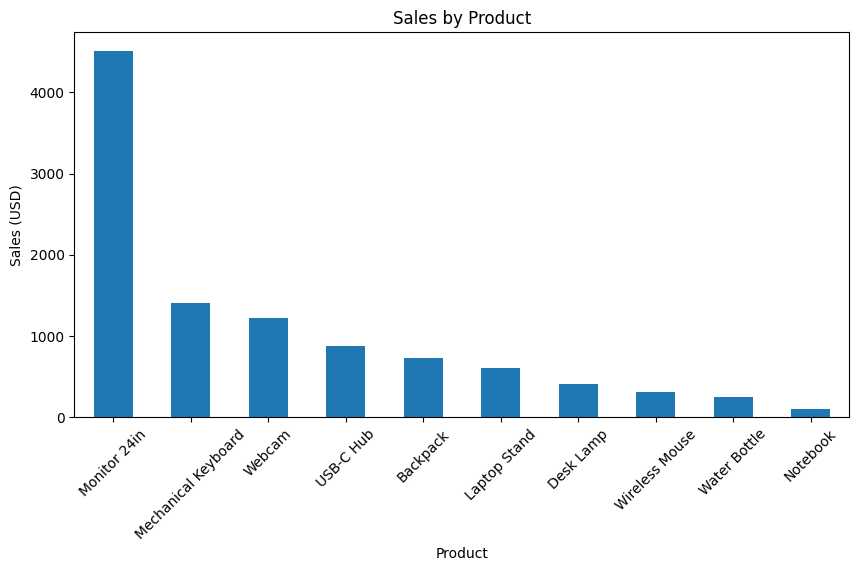

In [11]:
ventas_producto.plot(kind="bar", figsize=(10,5))

plt.title("Sales by Product")
plt.xlabel("Product")
plt.ylabel("Sales (USD)")
plt.xticks(rotation=45)
plt.show()

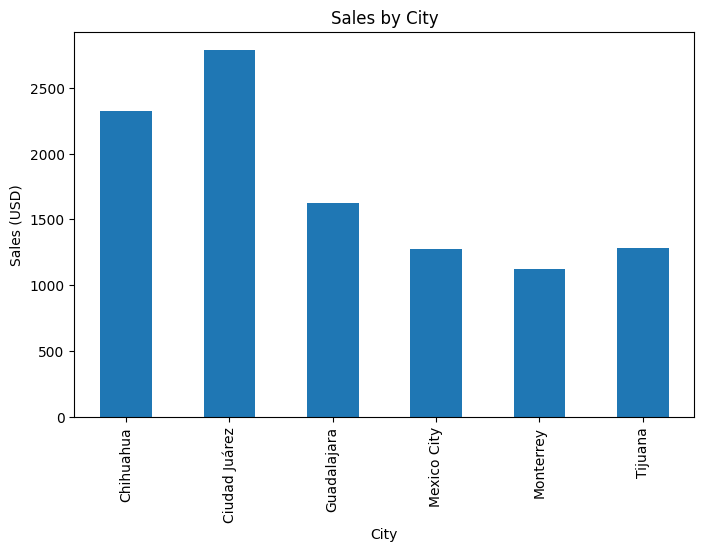

In [12]:
ventas_ciudad.plot(kind="bar", figsize=(8,5))

plt.title("Sales by City")
plt.xlabel("City")
plt.ylabel("Sales (USD)")
plt.show()

In [13]:
import sqlite3


conexion = sqlite3.connect("retail_sales.db")


df.to_sql("sales", conexion, if_exists="replace", index=False)

80

In [14]:
consulta = """
SELECT product, SUM(sales_usd) AS total_sales
FROM sales
GROUP BY product
ORDER BY total_sales DESC;
"""

resultado = pd.read_sql_query(consulta, conexion)

resultado

,product,total_sales
0,Monitor 24in,4516.75
1,Mechanical Keyboard,1407.63
2,Webcam,1219.20
3,USB-C Hub,872.00
4,Backpack,731.25
5,Laptop Stand,607.74
6,Desk Lamp,406.35
7,Wireless Mouse,314.50
8,Water Bottle,251.18
9,Notebook,94.55


In [15]:
consulta = """
SELECT city, SUM(sales_usd) AS total_sales
FROM sales
GROUP BY city
ORDER BY total_sales DESC;
"""

pd.read_sql_query(consulta, conexion)

,city,total_sales
0,Ciudad Juárez,2786.73
1,Chihuahua,2321.91
2,Guadalajara,1627.00
3,Tijuana,1286.90
4,Mexico City,1275.34
5,Monterrey,1123.27


In [ ]:
# Conclusions

1. The product with the highest sales was: Monitor 24in
2. The city with the highest sales was: Ciudad Juarez
3. Total sales were: $10421.15 USD.
